In [1]:
from sklearn import datasets, linear_model, neighbors

X_digits, y_digits = datasets.load_digits(return_X_y=True)
X_digits = X_digits / X_digits.max()

n_samples = len(X_digits)

X_train = X_digits[: int(0.9 * n_samples)]
y_train = y_digits[: int(0.9 * n_samples)]
X_test = X_digits[int(0.9 * n_samples) :]
y_test = y_digits[int(0.9 * n_samples) :]

knn = neighbors.KNeighborsClassifier()
logistic = linear_model.LogisticRegression(max_iter=1000)

print("KNN score: %f" % knn.fit(X_train, y_train).score(X_test, y_test))
print(
    "LogisticRegression score: %f"
    % logistic.fit(X_train, y_train).score(X_test, y_test)
)

KNN score: 0.961111
LogisticRegression score: 0.933333


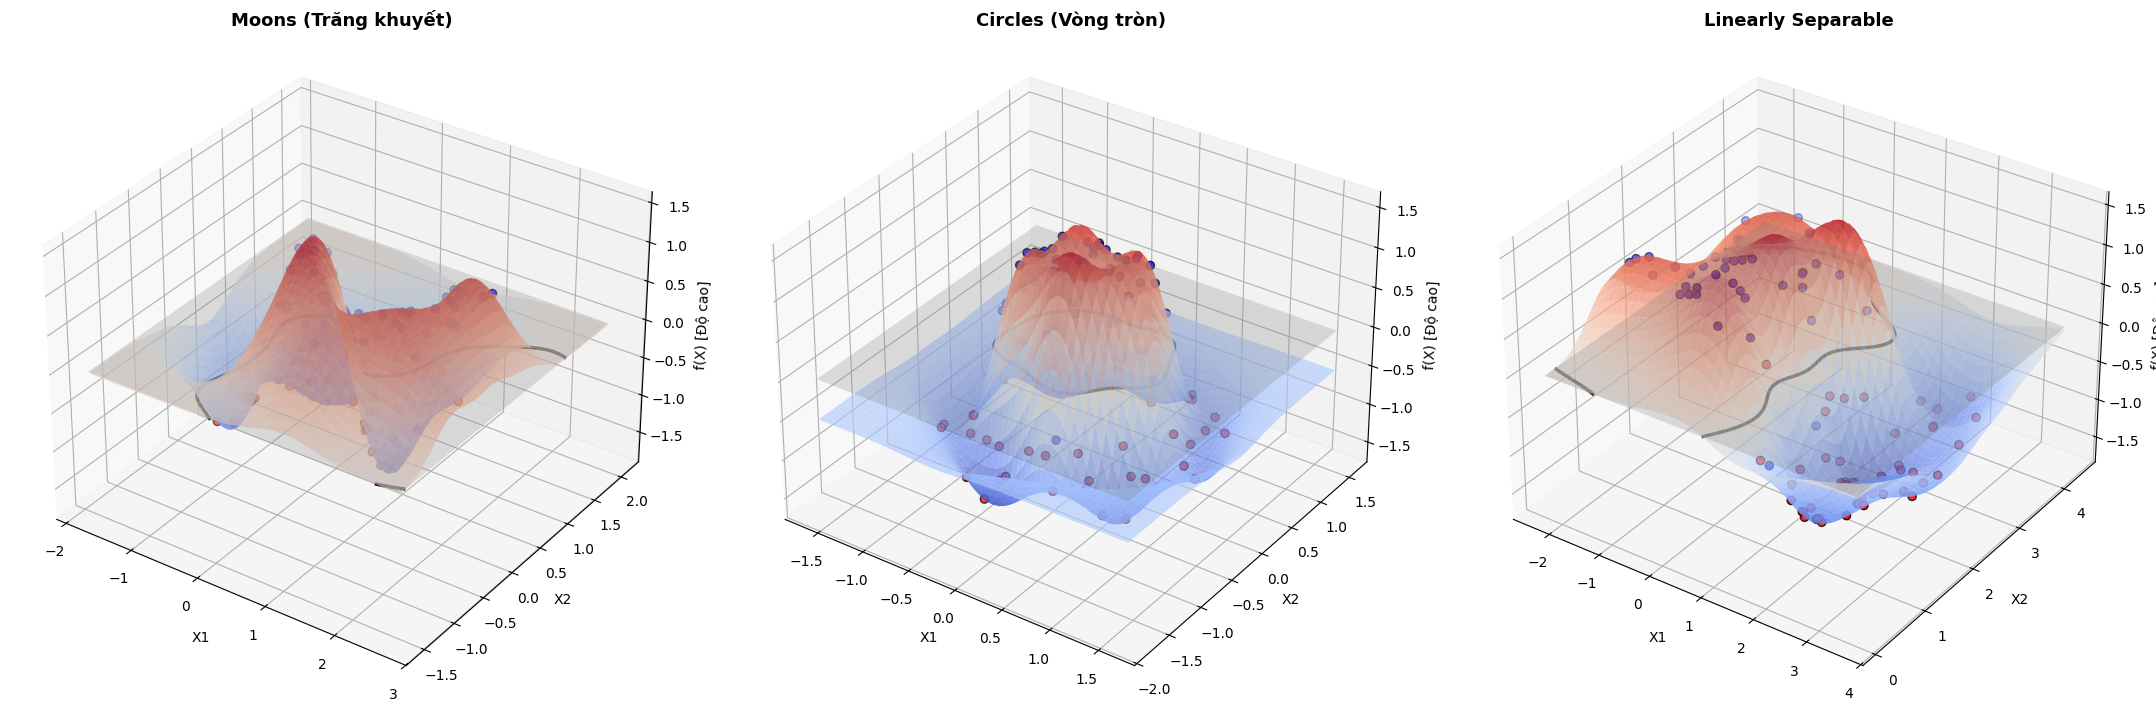

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Tạo 3 tập dữ liệu mẫu
datasets = [
    ("Moons (Trăng khuyết)", make_moons(noise=0.3, random_state=0)),
    ("Circles (Vòng tròn)", make_circles(noise=0.2, factor=0.5, random_state=1)),
]
# Dữ liệu phân tách tuyến tính
X_lin, y_lin = make_classification(
    n_features=2,
    n_redundant=0,
    n_informative=2,
    random_state=1,
    n_clusters_per_class=1,
)
rng = np.random.RandomState(2)
X_lin += 2 * rng.uniform(size=X_lin.shape)
datasets.append(("Linearly Separable", (X_lin, y_lin)))

# 2. Khởi tạo đồ thị 3D với 3 khung nhìn
fig = plt.figure(figsize=(22, 7))

for idx, (title, (X, y)) in enumerate(datasets):
    # Chuẩn hóa và huấn luyện RBF SVM
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma=2, C=1))
    clf.fit(X, y)

    # Tạo lưới tọa độ để tính độ cao Z = f(x1, x2)
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100)
    )

    # Tính giá trị hàm quyết định (Độ cao địa hình 3D)
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = fig.add_subplot(1, 3, idx + 1, projection="3d")

    # Vẽ bề mặt địa hình 3D (Surface)
    surf = ax.plot_surface(
        xx,
        yy,
        Z,
        cmap="coolwarm",
        alpha=0.65,
        edgecolor="none",
        antialiased=True,
    )

    # Vẽ mặt cắt phẳng tại mực nước biển z = 0 (Mặt phẳng phân chia)
    ax.plot_surface(
        xx,
        yy,
        np.zeros_like(Z),
        color="gray",
        alpha=0.25,
        shade=False,
    )

    # Vẽ đường mực nước biển z = 0 (Ranh giới quyết định 2D được chiếu lên)
    ax.contour(xx, yy, Z, levels=[0], colors="black", linewidths=2.5, offset=0)

    # Vẽ các điểm dữ liệu thực tế tại vị trí độ cao tương ứng
    z_points = clf.decision_function(X)
    ax.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        z_points[y == 0],
        color="red",
        s=35,
        edgecolors="k",
        label="Class 0 (Đỏ)",
    )
    ax.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        z_points[y == 1],
        color="blue",
        s=35,
        edgecolors="k",
        label="Class 1 (Xanh)",
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_zlabel("f(X) [Độ cao]")
    ax.view_init(elev=32, azim=-55)  # Góc nhìn 3D nghiêng từ trên xuống

plt.tight_layout()
plt.show()

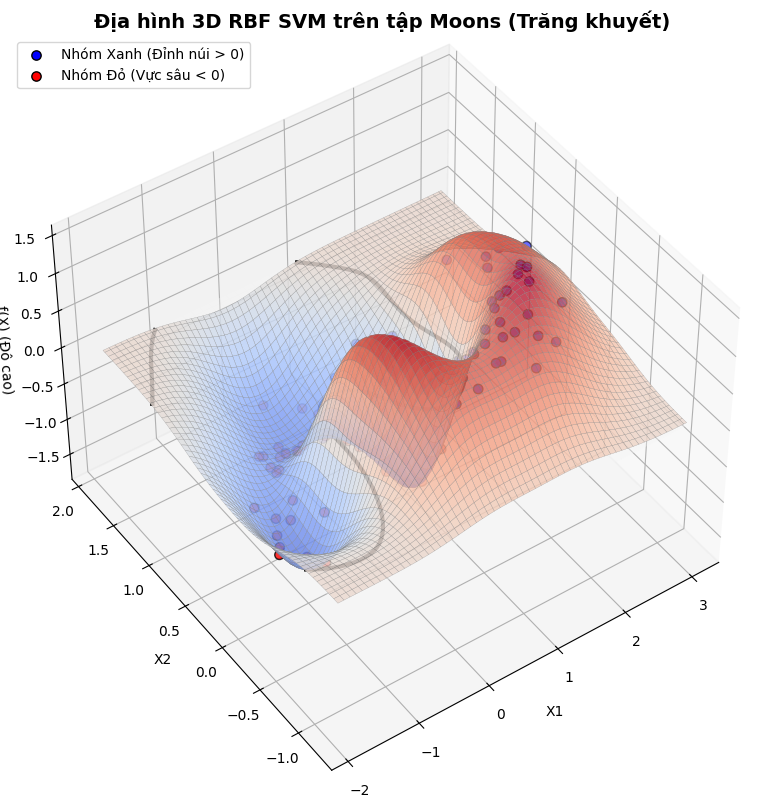

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Tạo tập dữ liệu Moons
X, y = make_moons(n_samples=100, noise=0.2, random_state=42)

# Huấn luyện RBF SVM
clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma=1.5, C=1.0))
clf.fit(X, y)

# Tạo lưới tọa độ mịn
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 120), np.linspace(y_min, y_max, 120)
)

Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
z_points = clf.decision_function(X)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

# 1. Vẽ bề mặt địa hình 3D
surf = ax.plot_surface(
    xx,
    yy,
    Z,
    cmap="coolwarm",
    alpha=0.75,
    rstride=2,
    cstride=2,
    linewidth=0.2,
    edgecolor="gray",
)

# 2. Vẽ mặt phẳng ranh giới z = 0 (Mực nước biển)
ax.plot_surface(
    xx, yy, np.zeros_like(Z), color="whitesmoke", alpha=0.35, shade=False
)

# 3. Đường ranh giới cắt ngang z = 0 (đường màu đen in đậm)
ax.contour(xx, yy, Z, levels=[0], colors="black", linewidths=3)

# 4. Vẽ các điểm dữ liệu thực tế
ax.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    z_points[y == 1],
    color="blue",
    s=45,
    edgecolors="k",
    label="Nhóm Xanh (Đỉnh núi > 0)",
)
ax.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    z_points[y == 0],
    color="red",
    s=45,
    edgecolors="k",
    label="Nhóm Đỏ (Vực sâu < 0)",
)

# Tinh chỉnh góc nhìn để thấy rõ 2 vệt trăng khuyết đối xứng
ax.view_init(elev=45, azim=-125)

ax.set_title(
    "Địa hình 3D RBF SVM trên tập Moons (Trăng khuyết)",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("f(X) (Độ cao)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()